In [63]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [64]:
# 도미 - 35
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어 - 14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]


1. 데이터 전처리

In [65]:
# 데이터 전처리

# 데이터 합해서 정리-> [[total_length,total_weight]] 으로 만들어야함
total_length = bream_length+smelt_length
total_weight = bream_weight+smelt_weight

In [66]:
# data= [[l,w] for l,w in zip(total_length,total_weight)] -> 리스트내포
# data2 =np. array(data) : 로 하면 + 등 사칙연산 가능

data = np.column_stack((total_length,total_weight))

# label =[1]*35+[0]*14
label=['도미']*35+['빙어']*14

In [67]:
# # 정규화 작업.

# # 표준점수 =( 특성값 - 평균값)/표준편차

# mean = np.mean(data, axis=0)
# std = np.std(data, axis=0)
# train_scaled = (data-mean)/std



In [68]:
# 정규화 작업전, 학습/테스트 데이터 분리
train_data, test_data, train_label, test_label=\
train_test_split(data, label)

In [69]:
#  데이터 학습
clf = KNeighborsClassifier()
clf.fit(train_data,train_label)

# 데이터 예측
result= clf.predict(test_data) #예측되어서 나온 값과 실제 정답과 비교

# 정확도
score = clf.score(test_data,test_label)
# score = metrics.accuracy_score(result,test_label)
print('정확도',score)

정확도 1.0


In [70]:
input1='25,120'
input1 = input1.split(',')
input1 # ['25', '120']

input2=list(map(float,input1))
input2 #[25.0, 120.0]

[25.0, 120.0]

In [71]:
## input을 받아서 도미인지 빙어인지 확인하시오
## 길이, 무게를 받아야함.

input1 = input('생선의 길이와 무게를 입력하시오. 예-25,120')
input1= input1.split(',')
input1 # ['25', '120']

input2=list(map(float,input1))
input2 #[25.0, 120.0]

result2= clf.predict([input2])
print('예측생선:',result2)

예측생선: ['빙어']


[머신러닝 확인사항]


In [72]:
# 정규화 작업.

# 표준점수 =( 특성값 - 평균값)/표준편차

mean = np.mean(data, axis=0)
std = np.std(data, axis=0)
train_scaled = (data-mean)/std
new_input = ([25,120]-mean)/std

# train_scaled    # -수치도 나옴.

In [81]:
#  자동으로 정규화 해줌

from sklearn.preprocessing import StandardScaler

ss=StandardScaler()             #정규화 선언

ss.fit(data)                    #정규화 학습
train_scaled=ss.transform(data) #정규화 변환

In [73]:
train_data,test_data,train_label,test_label = \
train_test_split(train_scaled,label)

In [74]:
#  데이터 학습
clf = KNeighborsClassifier()
clf.fit(train_data,train_label)

# 데이터 예측
result= clf.predict(test_data) #예측되어서 나온 값과 실제 정답과 비교

# 정확도
score = clf.score(test_data,test_label)
# score = metrics.accuracy_score(result,test_label)
print('정확도',score)

정확도 1.0


In [76]:
## input을 받아서 도미인지 빙어인지 확인하시오
## 길이, 무게를 받아야함.

input1 = input('생선의 길이와 무게를 입력하시오. 예-25,120')
input1= input1.split(',')
input1 # ['25', '120']

input2=list(map(float,input1))
input2 #[25.0, 120.0]

result2= clf.predict([input2])
print('예측생선:',result2)

예측생선: ['도미']


In [77]:
#  kneighbors 알고리즘 사용시 사용함.
distances,indexes = clf.kneighbors([new_input])
indexes

array([[ 6, 29, 10, 25,  3]])

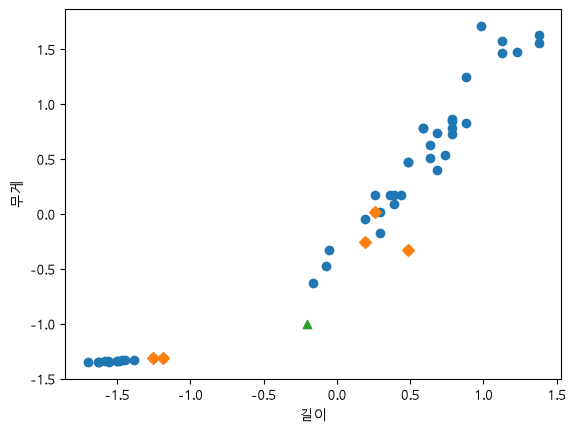

In [79]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(train_data[indexes,0],train_data[indexes,1],marker='D')
plt.scatter(new_input[0],new_input[1],marker='^')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()